# Giai đoạn 3c: Những ngày bất thường (anomaly detection)

**Loại công việc: data mining** (phát hiện bất thường, *anomaly / outlier detection*). Bước dựng "mức PM2.5 kỳ vọng theo thời tiết" ở mục 3 dùng một mô hình **ML** (hồi quy) làm công cụ; mục tiêu không phải dự báo mà là có một đường nền để đo độ lệch. Phần đối chiếu tin tức là **analysis** định tính.

Notebook 04–05 mô tả các ngày **điển hình**. Ở đây ta tìm các ngày **không giống điển hình**, vì chúng hay chứa thông tin mà thời tiết không giải thích được: một nguồn thải đột xuất (đốt rơm rạ, pháo hoa, cháy), một sự kiện xã hội (Tết, giãn cách), hoặc **lỗi đo**.

Ba loại bất thường (theo cách phân loại thường gặp trong giáo trình):
- **Point anomaly** (điểm bất thường): một ngày khác hẳn mọi ngày khác, ví dụ PM2.5 gần 0.
- **Contextual anomaly** (bất thường theo ngữ cảnh): bình thường nếu nhìn riêng, bất thường khi xét ngữ cảnh. 50 µg/m³ là chuyện thường vào tháng 1 nhưng bất thường vào một ngày tháng 7 gió mạnh. **Đây là loại chính của notebook.**
- **Collective anomaly** (bất thường tập thể): nhiều ngày liền cùng lệch một hướng, tạo thành một "đợt".

| Phương pháp | Ý tưởng | Ưu | Nhược |
|---|---|---|---|
| z-score trên giá trị thô | xa trung bình bao nhiêu độ lệch chuẩn | đơn giản | chỉ thấy ngày bẩn nhất mùa đông, lẫn mùa |
| Khử mùa (trừ khí hậu tháng) | lệch so với cùng tháng | khử mùa | không tính thời tiết của chính ngày đó |
| **Phần dư mô hình** (**chọn**) | lệch so với mức kỳ vọng từ mùa + thời tiết | đúng định nghĩa "bất thường theo ngữ cảnh"; giải thích được | phụ thuộc chất lượng mô hình |
| Isolation Forest | điểm dễ bị "cô lập" bằng các lát cắt ngẫu nhiên là bất thường | không cần mô hình, nhiều chiều | khó giải thích vì sao bất thường |
| LOF, DBSCAN | mật độ lân cận thấp | bắt được cụm nhỏ lạ | nhạy với thang đo và tham số |
| Khoảng cách tới tâm cụm | hình dạng ngày xa mọi kiểu điển hình | dùng lại kết quả notebook 04 | chỉ xét hình dạng |

Notebook dùng **phần dư mô hình** cho mức, **khoảng cách tới tâm cụm** cho hình dạng, và **Isolation Forest** làm đối chứng.

Đầu vào: `../phase1/data/clean/hanoi_daily.parquet`, `hanoi_hourly_enriched.parquet`, `data/day_clusters.csv`, `data/shape_centroids.csv`. Đầu ra: `data/day_anomaly.csv`, hình `reports/30_*` … `reports/37_*`.

**Nhắc lại:** một ngày "bất thường" chỉ là ngày **không khớp với mô hình**; lý do thật phải kiểm chứng bằng nguồn khác. Dữ liệu từ **một trạm** (Đại sứ quán Mỹ, Ba Đình).

In [1]:
from pathlib import Path
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import HistGradientBoostingRegressor, IsolationForest
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.model_selection import GroupKFold, cross_val_predict
from sklearn.decomposition import PCA

warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 100
pd.set_option("display.width", 200)

BASE = Path(os.environ.get("HANOI_AQ_DIR", ".."))
CLEAN = BASE / "phase1" / "data" / "clean"
REPORT = Path("reports"); REPORT.mkdir(exist_ok=True)
OUT = Path("data"); OUT.mkdir(exist_ok=True)
SEED = 0
HCOLS = [f"pm25_h{i:02d}" for i in range(24)]
SEASON = {12: "Đông", 1: "Đông", 2: "Đông", 3: "Xuân", 4: "Xuân", 5: "Hè", 6: "Hè", 7: "Hè", 8: "Hè", 9: "Hè", 10: "Thu", 11: "Thu"}

D = pd.read_parquet(CLEAN / "hanoi_daily.parquet"); D.index = pd.to_datetime(D.index)
h = pd.read_parquet(CLEAN / "hanoi_hourly_enriched.parquet")
cl = pd.read_csv(OUT / "day_clusters.csv", parse_dates=["date"]).set_index("date")
cent = pd.read_csv(OUT / "shape_centroids.csv", index_col=0)
print("bảng ngày:", D.shape, "| ngày đủ (>= 18 giờ đo thật):", int(D["day_ok"].sum()), "| ngày có nhãn cụm:", len(cl))

bảng ngày: (3358, 75) | ngày đủ (>= 18 giờ đo thật): 2322 | ngày có nhãn cụm: 2230


## 1. Kiểm tra chất lượng: bất thường do **lỗi đo** đến trước

Trước khi gọi một ngày là "sạch bất thường", cần loại khả năng thiết bị hỏng. Lần chạy đầu của notebook này (22/11/2026) phát hiện Giai đoạn 1 chỉ đổi giá trị **âm** thành NaN, còn các giờ 0–3 µg/m³ vẫn được giữ, và 17 ngày đủ có nhiều giờ gần 0. Quy tắc dưới đây sau đó đã được đưa về Giai đoạn 1 (mục 1.3 của notebook 01, cờ `flag_suspect_zero`), nên ô dưới giờ chủ yếu là **kiểm tra lại**. Lý do của quy tắc: ở Hà Nội, nhiều giờ liền dưới 3 µg/m³ là rất khó xảy ra về mặt vật lý (ngay cả mùa hè sau mưa, nồng độ nền khu vực thường vẫn trên vài µg/m³), trong khi đó lại là dấu hiệu quen thuộc của máy đo bị **trôi điểm 0** hoặc đang bảo trì.

Quy tắc (lựa chọn của notebook): ngày có **≥ 6 giờ** giá trị gốc ≤ 3 µg/m³ (tính cả giá trị âm) → gắn cờ `nghi_loi_do`. Không xóa, chỉ gắn cờ và loại khỏi phần tìm bất thường "thật". Lựa chọn khác: ngưỡng 8 giờ (ít ngày hơn, chắc chắn hơn) hoặc đòi thêm điều kiện "có giá trị âm".

In [2]:
raw = h["pm25_raw"].where(h["pm25_raw"] > -900)          # -999 = mã thiếu của nguồn
nz = (raw <= 3).groupby(h["date"]).sum(); nz.index = pd.to_datetime(nz.index)
neg = (raw < 0).groupby(h["date"]).sum(); neg.index = pd.to_datetime(neg.index)
D["n_near_zero"] = nz.reindex(D.index).fillna(0).astype(int)
D["n_negative"] = neg.reindex(D.index).fillna(0).astype(int)
NZ_MIN = 6
D["nghi_loi_do"] = D["n_near_zero"] >= NZ_MIN
print("phân bố số giờ <= 3 µg/m³ trong ngày (chỉ ngày >0):", D.loc[D["n_near_zero"] > 0, "n_near_zero"].value_counts().sort_index().to_dict())
flag = D[D["nghi_loi_do"] & D["day_ok"]]
print(f"ngày đủ bị gắn cờ nghi lỗi đo: {len(flag)}")
print(flag[["pm25_mean", "n_near_zero", "n_negative", "n_valid_h", "precip_sum", "ws_mean"]].round(1).to_string())

phân bố số giờ <= 3 µg/m³ trong ngày (chỉ ngày >0): {1: 43, 2: 15, 3: 16, 4: 7, 5: 7, 6: 5, 7: 1, 8: 2, 9: 2, 10: 3, 11: 1, 14: 1, 16: 2, 18: 2, 19: 1, 21: 1, 23: 1, 24: 4}
ngày đủ bị gắn cờ nghi lỗi đo: 3
            pm25_mean  n_near_zero  n_negative  n_valid_h  precip_sum  ws_mean
date                                                                          
2016-07-28        7.7            6           2         18       173.0      7.0
2017-01-12        6.5            6           0         18        15.3      5.4
2018-07-21       12.2            6           0         18        69.0      3.7


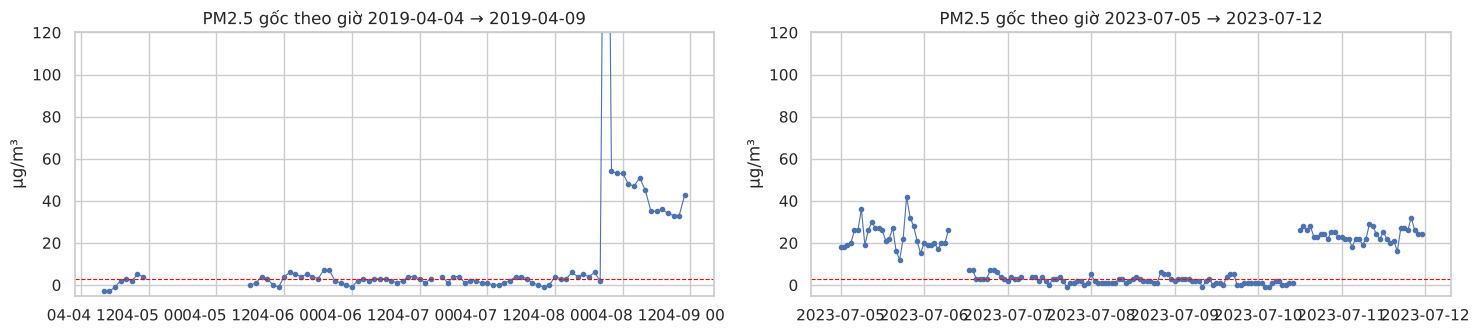

In [3]:
# Xem đường cong giờ gốc quanh hai cụm ngày nghi lỗi: 04/2019 và 07/2023
fig, axes = plt.subplots(1, 2, figsize=(15, 3.5))
for ax, (a, b) in zip(axes, [("2019-04-04", "2019-04-09"), ("2023-07-05", "2023-07-12")]):
    s = raw[(h.index >= pd.Timestamp(a, tz=h.index.tz)) & (h.index < pd.Timestamp(b, tz=h.index.tz))]
    ax.plot(s.index, s.values, marker=".", lw=0.8); ax.axhline(3, c="red", ls="--", lw=0.8)
    ax.set_title(f"PM2.5 gốc theo giờ {a} → {b}"); ax.set_ylabel("µg/m³"); ax.set_ylim(-5, 120)
plt.tight_layout(); plt.savefig(REPORT / "30_suspect_sensor.png"); plt.show()

**Đọc:** sau khi Giai đoạn 1 đã loại các giờ gần 0, chỉ còn **3 ngày đủ** vẫn khớp quy tắc (28/7/2016, 12/1/2017, 21/7/2018): mỗi ngày có đúng 6 giờ gần 0 đã bị đổi thành NaN nhưng vẫn còn 18 giờ khác, nên ngày vẫn "đủ". Cả ba là ngày mưa to; notebook vẫn để chúng ngoài mô hình cho chắc. 14 ngày còn lại của lần chạy đầu đã bị Giai đoạn 1 loại. Biểu đồ dưới dùng giá trị **gốc** để thấy hiện tượng. Tháng 4/2019, máy cho 0–5 µg/m³ (có cả giá trị âm) suốt khoảng hai ngày, rồi nhảy lên **358** trong một giờ và về ngay khoảng 50: dạng điển hình của thiết bị được hiệu chỉnh hoặc khởi động lại, không phải không khí sạch. Tháng 7/2023 có 4 ngày liền ở mức 0–4 µg/m³ dù trời gần như không mưa. Một số ngày bị gắn cờ là ngày **mưa rất to** (ví dụ 28/7/2016, 173 mm), nơi nồng độ rất thấp có thể là thật; vì vậy cờ chỉ là "nghi". Ngược lại, 13/3/2016 (4,7 µg/m³, ngay sau một ngày bị gắn cờ) lọt qua quy tắc vì chỉ có 5 giờ ≤ 3. Muốn khẳng định cần so với một trạm khác ở Hà Nội cùng thời điểm (OpenAQ có các trạm khác, đây là việc nên làm thêm).

Hệ quả: notebook 02–05 đã được chạy lại với dữ liệu mới (2.322 ngày đủ, 2.230 ngày có nhãn cụm). Kết luận chính không đổi; chi tiết trong lời giải thích của từng notebook.

## 2. Dữ liệu cho mô hình "mức kỳ vọng"

Ta cần ước lượng: *với mùa và thời tiết như hôm nay (và hôm qua), PM2.5 trung bình ngày thường là bao nhiêu?* Biến đầu vào:
- **Mùa**: `sin` và `cos` của ngày trong năm (mã hóa vòng tròn, để 31/12 và 1/1 nằm cạnh nhau).
- **Thời tiết hôm nay**: nhiệt độ, biên độ nhiệt, độ ẩm, mưa, áp suất, mây, bức xạ, gió (tốc độ, thành phần u/v), BLH.
- **Thời tiết hôm qua**: cùng các biến, lệch 1 ngày, vì bụi tích lũy qua nhiều ngày gió yếu.

**Cố ý không đưa vào**: điểm cháy, Tết, giãn cách, cuối tuần (biến về **nguồn thải** và **lịch**), và PM2.5 hôm qua. Nếu đưa vào, mô hình sẽ "giải thích hộ" chính các sự kiện ta muốn phát hiện. Như vậy phần dư = phần **thời tiết không giải thích được**, và ta sẽ dùng Tết / giãn cách như **phép thử**: nếu phương pháp đúng, những ngày đó phải có phần dư âm.

Đích: `log(PM2.5 TB ngày)` (theo Nhật ký 22/11, vì phân phối lệch phải). Phần dư trên thang log ≈ tỷ lệ: phần dư +0,7 nghĩa là bẩn gấp e^0,7 ≈ 2 lần mức kỳ vọng.

In [4]:
WX = ["t_mean", "t_range", "rh_mean", "precip_sum", "pressure_mean", "cloud_mean", "sw_sum", "ws_mean", "u_mean", "v_mean", "blh_mean", "blh_max"]
lag = D[WX].asfreq("D").shift(1).add_suffix("_hqua")       # asfreq: lệch đúng 1 ngày lịch, không lệch sang ngày có dữ liệu kế trước
D = D.join(lag)
doy = D.index.dayofyear
D["doy_sin"], D["doy_cos"] = np.sin(2 * np.pi * doy / 365.25), np.cos(2 * np.pi * doy / 365.25)
F_SEASON = ["doy_sin", "doy_cos"]
F_WX = F_SEASON + WX
F_ALL = F_WX + [c + "_hqua" for c in WX]

d = D[D["day_ok"] & ~D["nghi_loi_do"]].copy()
d["y"] = np.log(d["pm25_mean"].clip(lower=1))
d["season"] = d["month"].map(SEASON)
print("ngày dùng cho mô hình:", len(d))
print("thiếu theo cột (HistGradientBoosting xử lý NaN trực tiếp):", d[F_ALL].isna().sum().loc[lambda s: s > 0].to_dict())

ngày dùng cho mô hình: 2319
thiếu theo cột (HistGradientBoosting xử lý NaN trực tiếp): {'blh_mean': 179, 'blh_max': 179, 'blh_mean_hqua': 180, 'blh_max_hqua': 180}


## 3. Mô hình mức kỳ vọng và kiểm định chéo theo năm

Mô hình: **HistGradientBoostingRegressor** (cây tăng cường gradient, nhận NaN trực tiếp, bắt được tương tác như "gió yếu **và** khô"). Đối chứng: **Ridge** (hồi quy tuyến tính có phạt) trên cùng biến.

Điểm quan trọng: phần dư phải là **dự đoán ngoài mẫu** (*out-of-fold*). Nếu mô hình đã thấy chính ngày đó khi học, nó sẽ "học thuộc" cả ngày bất thường và phần dư bị thu nhỏ. Dùng **GroupKFold theo năm**: dự đoán cho năm 2020 do mô hình học trên các năm còn lại. Cách này cũng tránh rò rỉ giữa các ngày liền kề (ngày liền nhau rất giống nhau).

In [5]:
groups = d.index.year
cv = GroupKFold(n_splits=groups.nunique())
y = d["y"]
def r2(p): return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()

hgb = lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15, min_samples_leaf=20, random_state=SEED)
ridge = make_pipeline(SimpleImputer(), StandardScaler(), RidgeCV(alphas=np.logspace(-2, 3, 20)))
res = {}
for name, model, F in [("chỉ mùa", hgb(), F_SEASON), ("mùa + thời tiết hôm nay", hgb(), F_WX),
                       ("mùa + thời tiết hôm nay + hôm qua", hgb(), F_ALL), ("Ridge, cùng biến", ridge, F_ALL)]:
    p = cross_val_predict(model, d[F], y, groups=groups, cv=cv)
    res[name] = p
    print(f"{name:38s} R² ngoài mẫu = {r2(p):.3f}")
d["log_pred"] = res["mùa + thời tiết hôm nay + hôm qua"]
d["pred"] = np.exp(d["log_pred"])
d["resid"] = d["y"] - d["log_pred"]

chỉ mùa                                R² ngoài mẫu = 0.147


mùa + thời tiết hôm nay                R² ngoài mẫu = 0.595


mùa + thời tiết hôm nay + hôm qua      R² ngoài mẫu = 0.639
Ridge, cùng biến                       R² ngoài mẫu = 0.639


**Đọc:** riêng mùa giải thích ~15% biến động log PM2.5 giữa các ngày; thêm thời tiết hôm nay lên ~60%, thêm thời tiết hôm qua lên ~64%. Ridge tuyến tính cho kết quả bằng, nghĩa là quan hệ chủ yếu đơn giản; giữ HistGradientBoosting vì nó xử lý NaN của BLH mà không cần điền giá trị. Khoảng **36% còn lại** là phần thời tiết (theo dữ liệu tái phân tích) không giải thích được: nguồn thải thay đổi, vận chuyển từ xa, sai số của dữ liệu thời tiết, và nhiễu đo. Bất thường là phần đuôi của 40% này.

## 4. Từ phần dư đến "bất thường": z-score bền vững

Chuẩn hóa phần dư bằng **trung vị** và **MAD** (*median absolute deviation*, độ lệch tuyệt đối trung vị) thay vì trung bình và độ lệch chuẩn, vì chính các ngày bất thường sẽ thổi phồng độ lệch chuẩn:

z = (phần dư − trung vị) / (1,4826 × MAD)

(Hệ số 1,4826 làm MAD bằng độ lệch chuẩn khi dữ liệu chuẩn.) Ngưỡng: **|z| ≥ 2,5**. Nếu phần dư chuẩn, mỗi phía chỉ ~0,6% số ngày vượt ngưỡng này. Lựa chọn khác: |z| ≥ 3 (khắt khe hơn, rất ít ngày), hoặc lấy cố định 1% ngày lệch nhất mỗi phía.

MAD-sd của phần dư = 0.319 (≈ ×1.38 trên thang gốc)
bat_thuong
bình thường         2257
sạch hơn kỳ vọng      40
bẩn hơn kỳ vọng       22
tỷ lệ |z| >= 2,5: 2.67% (nếu chuẩn: ~1,2%)


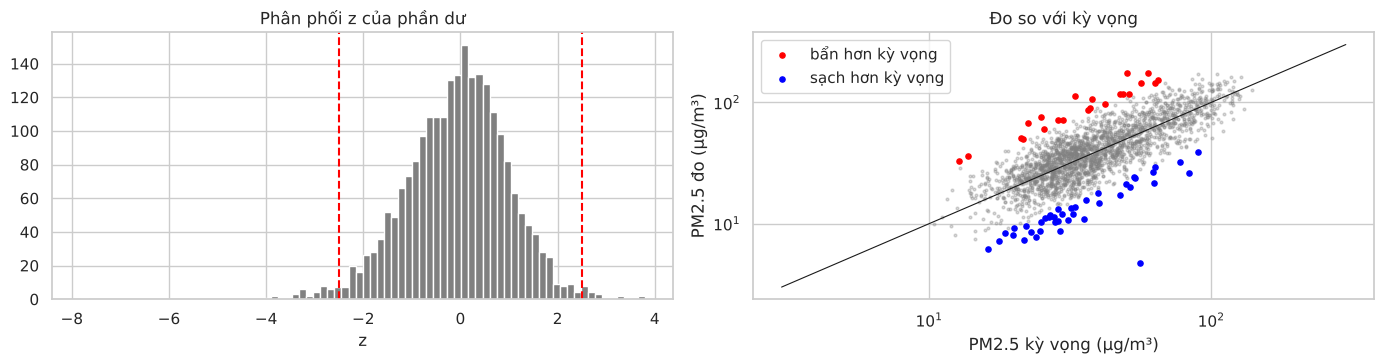

In [6]:
med = d["resid"].median(); mad = 1.4826 * (d["resid"] - med).abs().median()
d["z"] = (d["resid"] - med) / mad
Z = 2.5
d["bat_thuong"] = np.select([d["z"] >= Z, d["z"] <= -Z], ["bẩn hơn kỳ vọng", "sạch hơn kỳ vọng"], "bình thường")
print(f"MAD-sd của phần dư = {mad:.3f} (≈ ×{np.exp(mad):.2f} trên thang gốc)")
print(d["bat_thuong"].value_counts().to_string())
print("tỷ lệ |z| >= 2,5:", f"{(d['z'].abs() >= Z).mean():.2%}", "(nếu chuẩn: ~1,2%)")

fig, ax = plt.subplots(1, 2, figsize=(14, 3.8))
ax[0].hist(d["z"], bins=80, color="grey"); [ax[0].axvline(v, c="red", ls="--") for v in (-Z, Z)]
ax[0].set_title("Phân phối z của phần dư"); ax[0].set_xlabel("z")
ax[1].scatter(d["pred"], d["pm25_mean"], s=4, alpha=0.3, c="grey")
for lab, col in [("bẩn hơn kỳ vọng", "red"), ("sạch hơn kỳ vọng", "blue")]:
    m = d["bat_thuong"] == lab; ax[1].scatter(d.loc[m, "pred"], d.loc[m, "pm25_mean"], s=14, c=col, label=lab)
ax[1].plot([3, 300], [3, 300], c="k", lw=0.8); ax[1].set_xscale("log"); ax[1].set_yscale("log")
ax[1].set_xlabel("PM2.5 kỳ vọng (µg/m³)"); ax[1].set_ylabel("PM2.5 đo (µg/m³)"); ax[1].legend(); ax[1].set_title("Đo so với kỳ vọng")
plt.tight_layout(); plt.savefig(REPORT / "31_residual_z.png"); plt.show()

## 5. Phép thử bằng sự kiện đã biết (validation)

Nếu phương pháp đúng, những sự kiện làm **giảm nguồn thải** mà mô hình không biết (nghỉ Tết, giãn cách) phải có z âm; biến **đối chứng âm** (cuối tuần, EDA thấy không khác) phải có z quanh 0; ngày nhiều điểm cháy (nguồn thải mô hình không biết) nên có z dương.

                     nhóm  số ngày  z trung vị (nhóm)  z trung vị (còn lại)  tỷ lệ đo/kỳ vọng (trung vị)  % ngày bẩn bất thường
                 nghỉ Tết       55              -0.49                  0.01                         0.88                   3.64
                giãn cách       68              -0.25                  0.01                         0.95                   0.00
 cuối tuần (đối chứng âm)      662               0.04                 -0.02                         1.05                   1.21
cháy ĐBSH ≥ P90 của tháng      253               0.04                 -0.01                         1.05                   1.19


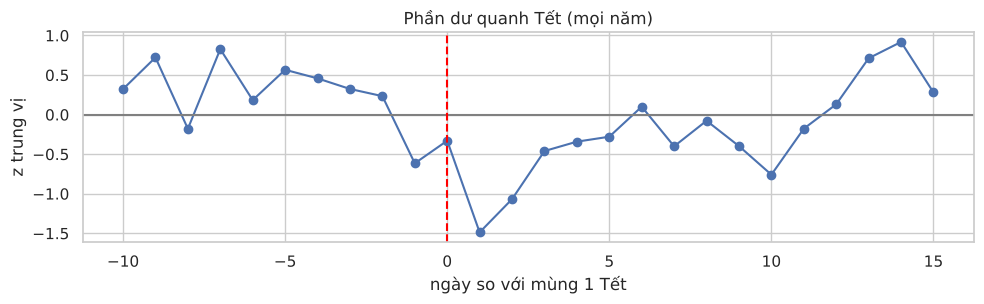

In [7]:
d["chay_nhieu"] = d["viirs_n_rrd"] >= d.groupby("month")["viirs_n_rrd"].transform(lambda s: s.quantile(0.9)).clip(lower=1)
tests = {
    "nghỉ Tết": d["is_tet_holiday"], "giãn cách": d["lockdown"], "cuối tuần (đối chứng âm)": d["is_weekend"],
    "cháy ĐBSH ≥ P90 của tháng": d["chay_nhieu"],
}
rows = []
for k, m in tests.items():
    m = m.astype(bool)
    rows.append({"nhóm": k, "số ngày": int(m.sum()), "z trung vị (nhóm)": d.loc[m, "z"].median(), "z trung vị (còn lại)": d.loc[~m, "z"].median(),
                 "tỷ lệ đo/kỳ vọng (trung vị)": np.exp(d.loc[m, "resid"].median()), "% ngày bẩn bất thường": (d.loc[m, "z"] >= Z).mean() * 100})
val = pd.DataFrame(rows).round(2); print(val.to_string(index=False))

# z theo ngày quanh Tết (tet_day = số ngày tính từ mùng 1)
t = d.dropna(subset=["tet_day"]); t = t[t["tet_day"].between(-10, 15)]
fig, ax = plt.subplots(figsize=(10, 3.2))
t.groupby("tet_day")["z"].median().plot(ax=ax, marker="o"); ax.axhline(0, c="grey"); ax.axvline(0, c="red", ls="--")
ax.set_xlabel("ngày so với mùng 1 Tết"); ax.set_ylabel("z trung vị"); ax.set_title("Phần dư quanh Tết (mọi năm)")
plt.tight_layout(); plt.savefig(REPORT / "32_tet_residual.png"); plt.show()

**Đọc:** nghỉ Tết có z trung vị khoảng −0,5 (đo thấp hơn kỳ vọng ~12% sau khi đã tính thời tiết; EDA so thô được −18%), giãn cách khoảng −0,25 (~5%), trong khi cuối tuần gần 0. Phương pháp **bắt được** các sự kiện giảm thải đã biết mà không được cho biết trước. Đường quanh Tết thấp nhất vào mùng 2–3 (z trung vị ~ −1,5).

Ngày nhiều điểm cháy **không** lệch rõ (z ≈ 0): ở mức ngày, số điểm cháy vệ tinh gần như không thêm thông tin sau khi đã biết thời tiết. Có thể do vệ tinh bỏ sót đám cháy nhỏ và dưới mây, do khói cần thời gian và hướng gió phù hợp mới tới trạm, hoặc vì đốt sinh khối thật sự chỉ đóng góp nhỏ. Dữ liệu này không phân biệt được các khả năng đó.

Đêm giao thừa không phải lúc nào cũng bẩn bất thường: trong 8 năm có dữ liệu, chỉ 2018 có z ≥ 2,5 vào ngày 30 Tết.

## 6. Bất thường theo tháng và theo đợt (collective anomaly)

Ngày "bẩn hơn kỳ vọng" có tập trung vào tháng nào không? Nếu có một nguồn thải theo mùa vụ mà mô hình thời tiết không biết (ví dụ đốt rơm rạ sau thu hoạch), các tháng đó sẽ nổi lên.

Đợt: chuỗi ngày **liên tiếp** có z ≥ 1,5 (ngưỡng thấp hơn vì đòi hỏi kéo dài), dài ≥ 3 ngày.

month_            1    2    3    4    5    6    7    8    9    10   11   12
% ngày z ≥ 2,5   1.3  2.7  1.1  0.0  0.0  2.2  1.2  0.0  1.0  1.4  0.0  0.5
% ngày z ≥ 1,5   8.6  4.9  6.4  2.8  5.3  6.7  8.5  2.4  6.2  9.9  4.9  4.2
% ngày z ≤ −2,5  0.9  1.1  2.1  0.0  1.8  1.7  6.1  1.2  2.4  2.3  1.8  0.0


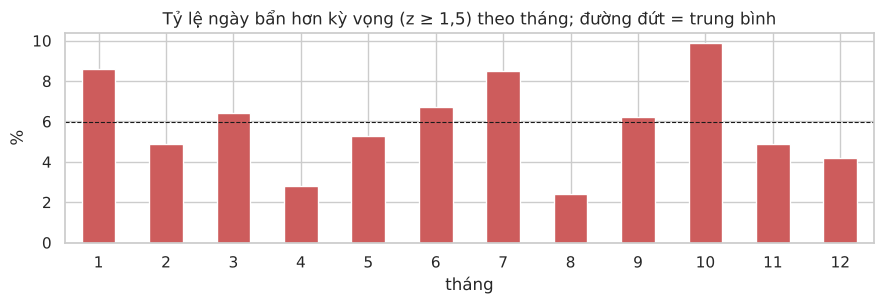


Số đợt >= 3 ngày liên tiếp có z >= 1,5: 7
   bat_dau   ket_thuc  so_ngay  z_tb  PM2.5 TB đo  PM2.5 TB kỳ vọng
2020-02-21 2020-02-23        3   2.6        146.9              61.1
2020-06-04 2020-06-06        3   2.1         59.0              29.1
2023-07-16 2023-07-18        3   2.0         45.2              22.9
2016-10-12 2016-10-15        4   2.0         66.7              34.1
2019-12-19 2019-12-21        3   2.0         69.4              35.6
2017-10-26 2017-10-30        5   2.0        106.9              56.0
2024-03-05 2024-03-09        5   1.8         94.5              52.0


In [8]:
d["month_"] = d.index.month
mon = pd.DataFrame({
    "% ngày z ≥ 2,5": d.groupby("month_")["z"].apply(lambda s: (s >= Z).mean() * 100),
    "% ngày z ≥ 1,5": d.groupby("month_")["z"].apply(lambda s: (s >= 1.5).mean() * 100),
    "% ngày z ≤ −2,5": d.groupby("month_")["z"].apply(lambda s: (s <= -Z).mean() * 100),
}).round(1)
print(mon.T.to_string())
fig, ax = plt.subplots(figsize=(9, 3.2)); mon[["% ngày z ≥ 1,5"]].plot(kind="bar", ax=ax, rot=0, legend=False, color="indianred")
ax.axhline((d["z"] >= 1.5).mean() * 100, c="k", ls="--", lw=0.8); ax.set_xlabel("tháng"); ax.set_ylabel("%")
ax.set_title("Tỷ lệ ngày bẩn hơn kỳ vọng (z ≥ 1,5) theo tháng; đường đứt = trung bình")
plt.tight_layout(); plt.savefig(REPORT / "33_anomaly_by_month.png"); plt.show()

# Đợt: các ngày lịch liên tiếp có z >= 1,5
zz = d["z"].asfreq("D")
hi = (zz >= 1.5).fillna(False)
run_id = (hi != hi.shift()).cumsum()
ep = (zz[hi].groupby(run_id[hi]).agg(bat_dau=lambda s: s.index.min().date(), ket_thuc=lambda s: s.index.max().date(), so_ngay="size", z_tb="mean"))
ep = ep[ep["so_ngay"] >= 3].sort_values("z_tb", ascending=False)
ep["PM2.5 TB đo"] = [d.loc[str(a):str(b), "pm25_mean"].mean() for a, b in zip(ep["bat_dau"], ep["ket_thuc"])]
ep["PM2.5 TB kỳ vọng"] = [d.loc[str(a):str(b), "pred"].mean() for a, b in zip(ep["bat_dau"], ep["ket_thuc"])]
print(f"\nSố đợt >= 3 ngày liên tiếp có z >= 1,5: {len(ep)}")
print(ep.round(1).to_string(index=False))

**Đọc:** trung bình ~6% số ngày có z ≥ 1,5. **Tháng 10** cao nhất (~10%), sau đó tháng 1 và tháng 7 (~8,5%); tháng 4, 8, 12 thấp nhất. Tháng 10 trùng vụ thu hoạch lúa mùa ở đồng bằng sông Hồng (mùa đốt rơm rạ, mục 9 dẫn nguồn). Tháng 6, vụ thu hoạch còn lại, không nổi bật về tỷ lệ, nhưng có 3 trong 15 ngày lệch mạnh nhất (19/6/2016, 6/6/2020, 15/6/2024) và một đợt 3 ngày (4–6/6/2020). Đây là **giả thuyết khớp**, không phải chứng minh.

Phía âm: tháng 7 có nhiều ngày **sạch** hơn kỳ vọng (~6%), thường là ngày mưa to. Mô hình dùng lượng mưa tái phân tích ~25 km, có thể lệch so với mưa thật tại trạm; ngoài ra một phần có thể là lỗi đo chưa bị gắn cờ.

## 7. Bất thường về **hình dạng**: ngày có nhịp lạ

Một ngày có thể bình thường về mức nhưng có đường cong lạ, ví dụ một đỉnh nhọn lúc nửa đêm. Đo bằng **khoảng cách Euclid** từ hình dạng của ngày (`log x − mean(log x)`, như notebook 04) tới **tâm cụm gần nhất**. Ngày trong top 1% khoảng cách = bất thường hình dạng.

ngưỡng top 1% khoảng cách = 3.43 | số ngày: 23
            pm25_mean  pm25_max  shape_dist  peak_hour  peak_ratio  n_spike_h  tet_day
date                                                                                  
2019-04-08      41.46     358.0        5.68          9       18.98          1      NaN
2018-07-31      48.55     323.0        5.20          3       12.68          1      NaN
2018-05-27      28.50     164.1        4.50          7        8.65          1      NaN
2018-05-02      17.46      29.9        4.48         10        2.46          0      NaN
2021-08-17      24.88     119.0        4.39          4        7.38          2      NaN
2021-08-12      21.17      42.0        4.21         11        2.78          0      NaN
2017-07-13      27.17     142.8        4.06          6        9.21          2      NaN
2017-09-10      22.74      46.7        4.00         13        2.94          0      NaN
2017-07-18      18.39      59.7        3.94          4        4.39          0      

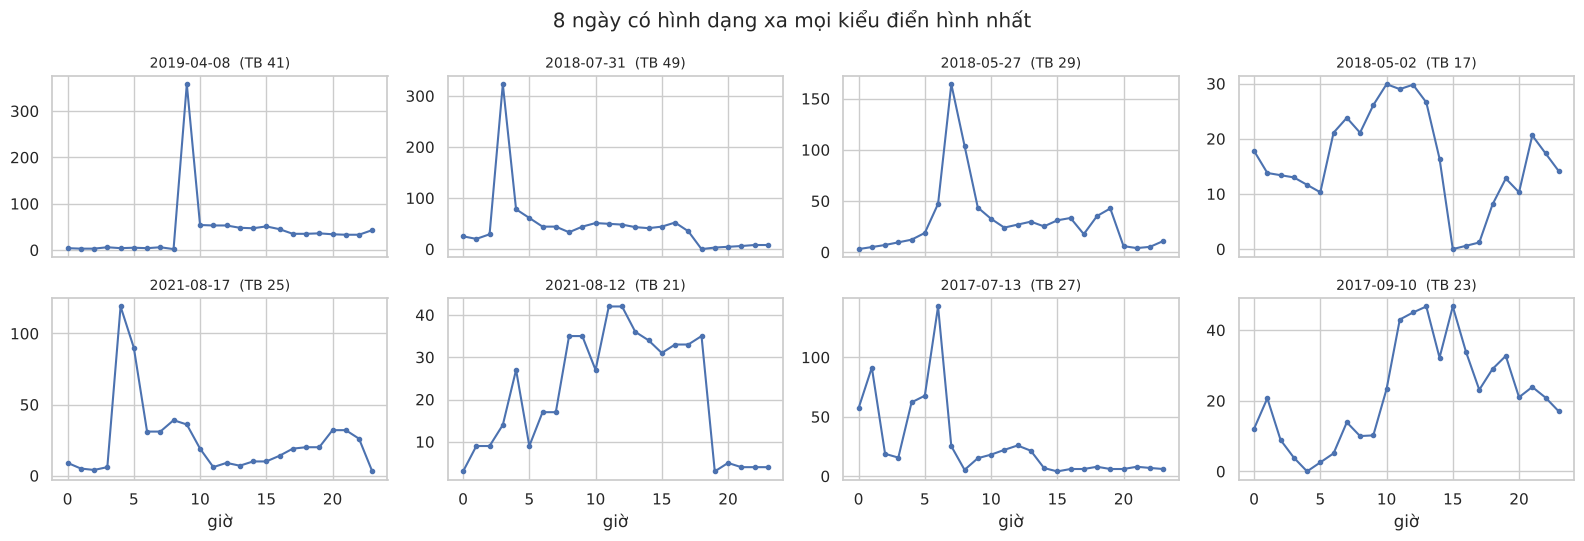

In [9]:
cdays = D[D["curve_complete"] & D["day_ok"] & ~D["nghi_loi_do"]].copy()
L = np.log(cdays[HCOLS].clip(lower=1)); S = L.sub(L.mean(axis=1), axis=0).values
C = np.log(cent.values)                              # tâm cụm được lưu ở dạng tỷ lệ x / trung bình hình học
C = C - C.mean(axis=1, keepdims=True)
dist = np.sqrt(((S[:, None, :] - C[None, :, :]) ** 2).sum(axis=2))
cdays["shape_dist"] = dist.min(axis=1)
cdays["peak_hour"] = S.argmax(axis=1)
cdays["peak_ratio"] = np.exp(S.max(axis=1))          # đỉnh gấp bao nhiêu lần trung bình hình học của ngày
thr = cdays["shape_dist"].quantile(0.99)
odd = cdays[cdays["shape_dist"] >= thr].sort_values("shape_dist", ascending=False)
print(f"ngưỡng top 1% khoảng cách = {thr:.2f} | số ngày: {len(odd)}")
print(odd[["pm25_mean", "pm25_max", "shape_dist", "peak_hour", "peak_ratio", "n_spike_h", "tet_day"]].round(2).to_string())

top = odd.head(8)
fig, axes = plt.subplots(2, 4, figsize=(16, 5.5), sharex=True)
for ax, (dt, r) in zip(axes.ravel(), top.iterrows()):
    ax.plot(range(24), r[HCOLS].values, marker=".")
    ax.set_title(f"{dt.date()}  (TB {r['pm25_mean']:.0f})", fontsize=10)
for ax in axes[-1]: ax.set_xlabel("giờ")
plt.suptitle("8 ngày có hình dạng xa mọi kiểu điển hình nhất"); plt.tight_layout(); plt.savefig(REPORT / "34_shape_outliers.png"); plt.show()

**Đọc:** có hai nhóm.
1. **Một đỉnh nhọn** trong 1–2 giờ, gấp 7–19 lần mức trung bình của ngày (ví dụ 358 µg/m³ lúc 9h ngày 8/4/2019, ngay sau đợt nghi lỗi đo ở mục 1; 323 lúc 3h ngày 31/7/2018). Có thể là một sự kiện thật rất ngắn và gần trạm (đốt rác, cháy) hoặc giá trị lỗi mà bộ lọc spike ở Giai đoạn 1 chưa bắt (nó chỉ gắn cờ một số trong đó).
2. **Ngày hè mức thấp** (10–25 µg/m³, nhiều nhất 2017–2018) với dao động không đều. Đây phần lớn là **hệ quả của cách biểu diễn**: trên thang log, chênh 10 → 30 µg/m³ cũng lớn như 100 → 300, nên ở mức thấp, nhiễu đo nhỏ thành hình dạng lạ. Bài học cho notebook 04: hình dạng của ngày rất sạch kém tin cậy hơn.

Không có ngày Tết nào trong nhóm này: pháo hoa giao thừa không đủ làm lệch hình dạng cả ngày ở trạm Ba Đình.

## 8. Đối chứng: Isolation Forest

**Isolation Forest** dựng nhiều cây chia ngẫu nhiên; điểm bất thường bị cô lập sau ít lần chia hơn. Không cần mô hình mức kỳ vọng. Đưa vào cùng một không gian: log mức, biên độ trong ngày, 3 thành phần chính (PCA) của hình dạng, và thời tiết chính (khử mùa bằng thứ hạng trong tháng). `contamination = 0,02` (2% ngày).

So sánh với hai cách trên: các phương pháp có chọn ra cùng những ngày không?

In [10]:
pcs = PCA(n_components=3, random_state=SEED).fit_transform(S)
G = pd.DataFrame(pcs, index=cdays.index, columns=["pc1", "pc2", "pc3"])
G["log_level"] = L.mean(axis=1); G["amp"] = S.std(axis=1)
for col in ["ws_mean", "precip_sum", "rh_mean", "t_range", "blh_mean"]:
    G[col + "_rank"] = cdays.groupby("month")[col].rank(pct=True)
G = G.fillna(0.5)
iso = IsolationForest(n_estimators=500, contamination=0.02, random_state=SEED).fit(StandardScaler().fit_transform(G))
cdays["iso_outlier"] = iso.predict(StandardScaler().fit_transform(G)) == -1

A = set(d.index[d["z"].abs() >= Z]) & set(cdays.index)          # phần dư (chỉ ngày có đường cong)
B = set(odd.index)                                              # hình dạng
I = set(cdays.index[cdays["iso_outlier"]])
j = lambda a, b: len(a & b) / len(a | b) if a | b else np.nan
print(f"phần dư |z|>=2,5: {len(A)} | hình dạng top 1%: {len(B)} | Isolation Forest 2%: {len(I)}")
print(f"trùng IF∩phần dư: {len(I & A)} (Jaccard {j(I, A):.2f}) | IF∩hình dạng: {len(I & B)} (Jaccard {j(I, B):.2f}) | phần dư∩hình dạng: {len(A & B)}")

phần dư |z|>=2,5: 56 | hình dạng top 1%: 23 | Isolation Forest 2%: 45
trùng IF∩phần dư: 5 (Jaccard 0.05) | IF∩hình dạng: 17 (Jaccard 0.33) | phần dư∩hình dạng: 3


**Đọc:** Isolation Forest trùng nhiều với cách **hình dạng** (Jaccard ~0,33) nhưng gần như không trùng với cách **phần dư** (~0,05). Lý do: nó xét mỗi biến như một chiều ngang hàng, nên điểm "lạ" là ngày có hình dạng hiếm hoặc tổ hợp thời tiết hiếm; nó không biết "75 µg/m³ vào một ngày tháng 7 mưa" là lạ, vì riêng 75 µg/m³ thì rất bình thường. Đó chính là khác biệt giữa **point anomaly** và **contextual anomaly**. Phương pháp phần dư dễ giải thích hơn ("bẩn gấp 3 lần thời tiết cho phép"), nên dùng làm danh sách chính.

## 9. Danh sách ngày bất thường và đối chiếu tin tức

Bảng dưới là các ngày **bẩn hơn kỳ vọng** nhất (không tính ngày nghi lỗi đo). Sau đó là phần đối chiếu với báo chí, tra cứu ngày 22/11/2026.

In [11]:
cols = ["pm25_mean", "pred", "z", "ws_mean", "precip_sum", "viirs_n_rrd", "viirs_n_north", "tet_day"]
top_hi = d.sort_values("z", ascending=False).head(15)[cols].rename(columns={"pm25_mean": "đo", "pred": "kỳ vọng"})
top_hi["tỷ lệ"] = top_hi["đo"] / top_hi["kỳ vọng"]
print("15 ngày bẩn hơn kỳ vọng nhất:\n", top_hi.round(1).to_string())
top_lo = d.sort_values("z").head(10)[cols].rename(columns={"pm25_mean": "đo", "pred": "kỳ vọng"})
print("\n10 ngày sạch hơn kỳ vọng nhất (đã loại ngày nghi lỗi đo):\n", top_lo.round(1).to_string())

15 ngày bẩn hơn kỳ vọng nhất:
                đo  kỳ vọng    z  ws_mean  precip_sum  viirs_n_rrd  viirs_n_north  tet_day  tỷ lệ
date                                                                                            
2020-01-14  175.0     50.4  3.8      2.5         0.8          0.0           25.0    -11.0    3.5
2024-06-15  112.9     32.9  3.8      2.1         0.1          0.0            3.0      NaN    3.4
2016-06-19   68.1     22.4  3.4      3.2         0.1          1.0           28.0      NaN    3.0
2020-07-28   75.5     25.0  3.4      1.8        19.4          0.0            0.0      NaN    3.0
2020-02-21  176.0     59.6  3.3      2.3         1.7         22.0           50.0      NaN    3.0
2017-03-01  106.1     37.8  3.1      2.5         1.4          0.0            0.0      NaN    2.8
2024-07-03   36.2     13.7  2.9      3.0        26.9          0.0            0.0      NaN    2.6
2020-10-29   32.8     12.8  2.9      5.1        15.9          0.0            0.0      NaN    2.6

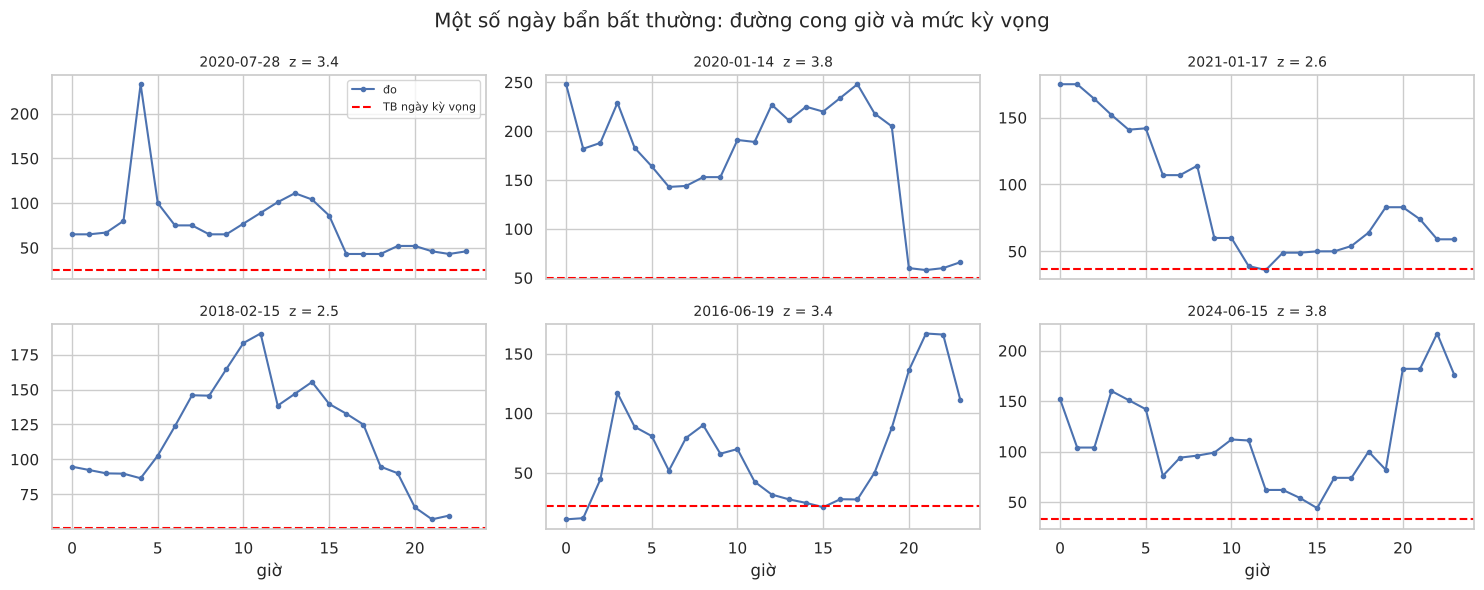

In [12]:
# Đường cong giờ của một số ngày đã đối chiếu tin tức
show = ["2020-07-28", "2020-01-14", "2021-01-17", "2018-02-15", "2016-06-19", "2024-06-15"]
fig, axes = plt.subplots(2, 3, figsize=(15, 6), sharex=True)
for ax, day in zip(axes.ravel(), show):
    r = D.loc[day]
    ax.plot(range(24), r[HCOLS].values, marker=".", label="đo")
    ax.axhline(d.loc[day, "pred"], c="red", ls="--", label="TB ngày kỳ vọng")
    ax.set_title(f"{day}  z = {d.loc[day, 'z']:.1f}", fontsize=10)
axes[0, 0].legend(fontsize=8)
for ax in axes[-1]: ax.set_xlabel("giờ")
plt.suptitle("Một số ngày bẩn bất thường: đường cong giờ và mức kỳ vọng"); plt.tight_layout(); plt.savefig(REPORT / "35_examples.png"); plt.show()

### Đối chiếu với tin tức (tra cứu 22/11/2026)

| Ngày (z) | Quan sát trong dữ liệu | Tin tức / nguồn | Mức khớp |
|---|---|---|---|
| **28/7/2020** (z = 3,4) | 75 µg/m³ giữa mùa hè, kỳ vọng ~25; đỉnh 233 lúc 4h sáng | Sáng 28/7/2020, Hà Nội đứng đầu danh sách ô nhiễm thế giới của IQAir (AQI ~173 lúc 7h47); hơn 80 điểm đo PAM Air ở mức đỏ/tím. Không có bài phân tích nguyên nhân riêng cho ngày này. [RFA](https://www.rfa.org/vietnamese/news/vietnamnews/hanoi-is-the-most-polluted-air-in-the-world-in-the-morning-of-july-28-07282020092143.html), [VOV English](https://english.vov.vn/en/society/air-pollution-in-hanoi-again-exceeds-red-warning-level-769158.vov) | **Khớp theo ngày**, từ các mạng đo khác (IQAir có thể dùng cả trạm Đại sứ quán, nên không hoàn toàn độc lập; PAM Air là mạng riêng) |
| **14/1/2020** (z = 3,8) | 175 µg/m³, kỳ vọng ~50 | Tháng 1/2020 nhiều ngày ô nhiễm nặng; theo Tổng cục Môi trường, từ 1/1 đến 18/2/2020 khoảng 50% số ngày ở Hà Nội có AQI > 100. Không tìm thấy bài riêng cho 14/1. [Tuổi Trẻ](https://tuoitre.vn/o-nhiem-khong-khi-tai-ha-noi-vuot-qua-bac-kinh-20200227093713457.htm), [VOH](https://voh.com.vn/xa-hoi/chat-luong-khong-khi-ha-noi-canh-bao-o-nhiem-do-dung-thu-4-the-gioi-575529.html) | Khớp theo **giai đoạn**, chưa theo ngày |
| **7/1 và 17/1/2021** (z 2,5–2,6) | ~89 µg/m³, kỳ vọng ~37–40 | Đầu tháng 1/2021 Sở TN&MT Hà Nội ghi nhận AQI tăng từ 1/1, sáng 5/1 chạm "rất xấu" ở 35 trạm; nguyên nhân được nêu: không khí lạnh suy yếu, gió yếu, giao thông tăng sau Tết Dương lịch, rác thải, đốt rơm rạ, xây dựng. [RFA](https://www.rfa.org/vietnamese/news/vietnamnews/air-pollution-in-hanoi-at-dangerous-level-01052021074354.html), [Nhân Dân](https://nhandan.vn/chat-luong-khong-khi-suy-giam-manh-o-ha-noi-va-mien-bac-post630818.html) | Khớp theo **giai đoạn**; nguồn nêu cả yếu tố thời tiết lẫn nguồn thải |
| **15/2/2018** (z = 2,5) | 118 µg/m³ (kỳ vọng ~51), ngày 30 Tết Mậu Tuất | Hà Nội bắn pháo hoa 0h00–0h15 ngày 16/2/2018 (Kế hoạch 33/KH-UBND). Nhưng đỉnh trong dữ liệu ở **khoảng 10–11h trưa ngày 15**, không phải lúc giao thừa, nên pháo hoa không giải thích được; đốt vàng mã cúng tất niên ban ngày là một giả thuyết chưa kiểm chứng. [LuatVietnam](https://luatvietnam.vn/van-hoa/ke-hoach-33-kh-ubnd-uy-ban-nhan-dan-tp-ha-noi-158969-d2.html) | Khớp về **lịch**, **không** khớp về giờ |
| **15/6/2024, 19/6/2016, 6/6/2020, 6/6/2021** (z 2,5–3,8) | 68–113 µg/m³ khi kỳ vọng 22–42; một đợt 4–6/6/2020 | Nghiên cứu của ĐHQGHN: hai mùa đốt rơm rạ chính quanh Hà Nội là tháng 6 và tháng 10, tập trung tháng 6. Các bài báo về cảnh báo đêm do đốt rơm rạ (Tổng cục Môi trường, 9/6) và kiểm tra 20 huyện 11–17/6 không ghi rõ năm trong phần tìm được. Không tìm được bài riêng cho các ngày này. [VNU J. Science](https://js.vnu.edu.vn/NST/article/download/5192/4514), [Báo Đầu tư](https://baodautu.vn/sau-canh-bao-gia-tang-o-nhiem-ve-dem-ha-noi-kiem-tra-dot-rom-ra-d123985.html), [VOV English](https://english.vov.vn/en/society/hanoi-capital-sees-air-pollution-worsen-as-residents-burn-straw-864103.vov). Ngày 19/6/2016 và 15/6/2024 có đỉnh **buổi tối** (20–22h), hợp với cảnh báo "ô nhiễm tăng về đêm do đốt rơm". | Khớp về **mùa vụ** và giờ, chưa xác nhận theo ngày |
| **6–7/4/2019, 7–10/7/2023** (z rất âm) | 0–5 µg/m³ nhiều giờ, có giá trị âm, nhảy 358 | Không có tin tức (không kỳ vọng có) | **Nghi lỗi đo**, cần so với trạm khác |

**Kết luận phần đối chiếu:** ngày bất thường mạnh nhất có tin tức xác nhận **theo đúng ngày** là 28/7/2020; các ngày tháng 1/2020 và 1/2021 khớp với các đợt ô nhiễm được báo chí ghi nhận nhưng chỉ theo giai đoạn. Nhóm ngày tháng 6 gợi ý đốt rơm rạ, nhưng mới khớp về mùa vụ. Báo chí thường dẫn AQI từ IQAir/PAM Air, là mạng đo khác, nên đây là xác nhận **độc lập một phần**.

## 10. Lưu kết quả

In [13]:
out = d[["pm25_mean", "pred", "resid", "z", "bat_thuong"]].join(cdays[["shape_dist", "peak_hour", "peak_ratio", "iso_outlier"]], how="left")
out["shape_outlier"] = out.index.isin(odd.index)
flag_out = D.loc[D["nghi_loi_do"] & D["day_ok"], ["pm25_mean"]].assign(bat_thuong="nghi lỗi đo")
out = pd.concat([out, flag_out]).sort_index()
out["nghi_loi_do"] = out["bat_thuong"] == "nghi lỗi đo"
out.index.name = "date"
out.round(4).to_csv(OUT / "day_anomaly.csv")
ep.to_csv(REPORT / "36_episodes.csv", index=False)
top_hi.round(2).to_csv(REPORT / "37_top_anomalies.csv")
print(out["bat_thuong"].value_counts().to_string()); print("đã lưu", OUT / "day_anomaly.csv")

bat_thuong
bình thường         2257
sạch hơn kỳ vọng      40
bẩn hơn kỳ vọng       22
nghi lỗi đo            3
đã lưu data/day_anomaly.csv


## 11. Tóm tắt, giới hạn, quyết định

**Phương pháp (mining):** mức kỳ vọng của mỗi ngày = mô hình HistGradientBoosting từ mùa + thời tiết hôm nay và hôm qua (không dùng biến nguồn thải hay lịch), dự đoán ngoài mẫu theo từng năm (R² 0,64). Bất thường theo ngữ cảnh = phần dư chuẩn hóa bằng trung vị/MAD, |z| ≥ 2,5. Thêm: cờ nghi lỗi đo (≥ 6 giờ ≤ 3 µg/m³), bất thường hình dạng (top 1% khoảng cách tới tâm cụm), đợt (≥ 3 ngày liền z ≥ 1,5), và Isolation Forest làm đối chứng.

**Kết quả chính:**
1. **Lỗi đo đến trước:** lần chạy đầu tìm ra 17 ngày nghi lỗi đo (nhiều giờ 0–3 µg/m³, có giá trị âm, có lúc nhảy lên 358). Quy tắc đã được đưa về Giai đoạn 1; 14 ngày bị loại, 3 ngày mưa to vẫn đủ giờ nhưng được để ngoài mô hình.
2. **Phép thử đạt:** không được cho biết trước, phương pháp vẫn thấy nghỉ Tết thấp hơn kỳ vọng ~12% và giãn cách ~5%, còn cuối tuần (đối chứng âm) không lệch.
3. **22 ngày bẩn hơn kỳ vọng** (|z| ≥ 2,5, đo gấp 2,4–3,5 lần mức thời tiết cho phép) và 40 ngày sạch hơn kỳ vọng. Phần đuôi dày hơn phân phối chuẩn (2,7% so với 1,2%), nghĩa là có những ngày thật sự khác thường chứ không chỉ là nhiễu.
4. **Đối chiếu tin tức:** 28/7/2020 khớp **đúng ngày** (Hà Nội đứng đầu bảng ô nhiễm IQAir sáng hôm đó); 14/1/2020 và tháng 1/2021 khớp với các đợt ô nhiễm được báo chí ghi nhận nhưng chỉ theo giai đoạn; 15/2/2018 là ngày 30 Tết Mậu Tuất nhưng đỉnh rơi vào buổi trưa, không phải giờ pháo hoa. Các ngày tháng 6 lệch mạnh trùng mùa đốt rơm rạ sau vụ chiêm xuân, nhưng chưa có nguồn xác nhận theo ngày.
5. **Theo tháng:** tháng 10 có tỷ lệ ngày bẩn hơn kỳ vọng cao nhất (~10% so với trung bình ~6%), trùng vụ thu hoạch lúa mùa. Số điểm cháy vệ tinh theo ngày lại gần như không liên hệ với phần dư.
6. **Hình dạng lạ** chủ yếu là đỉnh nhọn 1–2 giờ (có thể lỗi đo hoặc nguồn rất gần) và ngày hè mức thấp, nơi thang log phóng đại nhiễu nhỏ.

**Giới hạn:**
- Một trạm; tin tức thường dẫn IQAir/PAM Air, nên xác nhận chỉ độc lập một phần. Không kiểm tra được với trạm thứ hai trong notebook này.
- "Bất thường" = không khớp mô hình. Mô hình dùng thời tiết tái phân tích ERA5 (~25 km), nên một số ngày "bất thường" có thể chỉ là thời tiết thật tại trạm khác với tái phân tích (đặc biệt mưa rào cục bộ mùa hè).
- Ngưỡng (6 giờ ≤ 3 µg/m³; |z| ≥ 2,5; top 1%; contamination 2%) là lựa chọn của dự án; đổi ngưỡng sẽ đổi danh sách, nhưng các ngày lệch mạnh nhất vẫn giữ nguyên.
- Các giải thích như "đốt rơm rạ", "pháo hoa" là **giả thuyết khớp với lịch và tin tức**, không phải nguyên nhân đã chứng minh.

**Quyết định nên ghi vào "Nhật ký quyết định":**
- Giai đoạn 1: trong ngày có ≥ 6 giờ PM2.5 gốc ≤ 3 µg/m³, đổi các giờ đó thành NaN (`flag_suspect_zero`); đã chạy lại notebook 01–06.
- Bất thường theo ngữ cảnh = phần dư của mô hình thời tiết (không dùng biến nguồn thải/lịch), kiểm định chéo theo năm, ngưỡng |z| ≥ 2,5 trên z bền vững (trung vị/MAD).
- Dùng Tết, giãn cách và cuối tuần làm phép thử cho phương pháp.

**Bước tiếp theo theo brief:** Giai đoạn 4 (tùy chọn) dự báo PM2.5 ngày hôm sau, hoặc bài viết ngắn cho người không chuyên. Trước đó nên so trạm Đại sứ quán với một trạm OpenAQ khác để kiểm tra các ngày nghi lỗi đo.